# Lab 09 - Mạng nơ-ron nhiều lớp (6 bài tập)
![Python](https://img.shields.io/badge/Python-3776AB?style=flat-square&logo=python&logoColor=white) ![NumPy](https://img.shields.io/badge/NumPy-013243?style=flat-square&logo=numpy&logoColor=white) ![Pandas](https://img.shields.io/badge/Pandas-150458?style=flat-square&logo=pandas&logoColor=white) ![Matplotlib](https://img.shields.io/badge/Matplotlib-11557c?style=flat-square) ![scikit-learn](https://img.shields.io/badge/scikit--learn-F7931E?style=flat-square&logo=scikit-learn&logoColor=white) ![Jupyter Notebook](https://img.shields.io/badge/Jupyter_Notebook-F37626?style=flat-square&logo=jupyter&logoColor=white)


* **Họ và tên:** Huỳnh Hữu Phúc
* **MSSV:** 2474802010314
* **Môn:** Học Máy Và Ứng Dụng
* **LHP:** 261_71ITAI41203_0101
* **GVHD:** ThS. Nguyễn Thái Anh ([GitHub](https://github.com/AnhNguyenVLU))

## Bài 1. Tự dự đoán bằng trọng số đã học

**Đề bài**

Huấn luyện lại MLP có 8 nơ-ron ẩn trên bộ XOR như mục 3. Lấy trọng số và hệ số chặn, dùng NumPy tính lan truyền tiến cho năm điểm kiểm tra đầu tiên với ReLU ở lớp ẩn và sigmoid ở đầu ra. So sánh với cột xác suất nhãn 1 của `predict_proba`.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

du_lieu = pd.read_csv("data/xor.csv")
dac_trung = du_lieu[["x1", "x2"]]
nhan = du_lieu["nhan"]
X_hoc, X_kiem_tra, y_hoc, _ = train_test_split(
    dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan
)
mlp = MLPClassifier(
    hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0
).fit(X_hoc, y_hoc)

nam_diem = X_kiem_tra.iloc[:5]
X = nam_diem.to_numpy()
W_an, W_ra = mlp.coefs_
b_an, b_ra = mlp.intercepts_

# Lan truyền tiến bằng NumPy trên từng hàng của ma trận đầu vào.
z_an = X @ W_an + b_an
h = np.maximum(0, z_an)
z_ra = (h @ W_ra + b_ra).ravel()
xac_suat_tu_tinh = 1 / (1 + np.exp(-z_ra))

assert mlp.classes_[1] == 1
xac_suat_thu_vien = mlp.predict_proba(nam_diem)[:, 1]
chenh_lech = np.abs(xac_suat_tu_tinh - xac_suat_thu_vien)
np.testing.assert_allclose(xac_suat_tu_tinh, xac_suat_thu_vien, atol=1e-12, rtol=0)

print(f"W ẩn {W_an.shape}, b ẩn {b_an.shape}, W ra {W_ra.shape}, b ra {b_ra.shape}")
print(f"Ma trận kích hoạt ẩn: {h.shape}, vector logit đầu ra: {z_ra.shape}")
bang = nam_diem.assign(
    z_ra=z_ra, p_numpy=xac_suat_tu_tinh, p_sklearn=xac_suat_thu_vien, sai_so=chenh_lech
)
print(bang.to_string(float_format=lambda x: f"{x:.12g}"))
print(f"Sai khác tuyệt đối lớn nhất: {chenh_lech.max():.3e}")

# Theo dõi toàn bộ các nút của điểm đầu tiên.
print(f"\nĐiểm đầu tiên có chỉ số CSV {nam_diem.index[0]}")
print(f"z ẩn: {np.round(z_an[0], 6)}")
print(f"h sau ReLU: {np.round(h[0], 6)}")
print(f"z ẩn nơ-ron đầu = {X[0, 0]:.4f} * ({W_an[0, 0]:.6f}) "
      f"+ {X[0, 1]:.4f} * ({W_an[1, 0]:.6f}) + ({b_an[0]:.6f}) "
      f"= {z_an[0, 0]:.6f}")
print(f"z đầu ra = {z_ra[0]:.6f}, sigmoid(z) = {xac_suat_tu_tinh[0]:.12f}")

W ẩn (2, 8), b ẩn (8,), W ra (8, 1), b ra (1,)
Ma trận kích hoạt ẩn: (5, 8), vector logit đầu ra: (5,)
         x1      x2           z_ra         p_numpy       p_sklearn            sai_so
338  0.3319 -0.5595  -4.0245324704 0.0175579853725 0.0175579853725                 0
342 -0.7016 -0.8251  7.47782212578  0.999434831959  0.999434831959                 0
40   0.5155 -0.0052  1.35123251701  0.794331056599  0.794331056599                 0
231 -0.6036  0.2726 -1.86259483284  0.134400889648  0.134400889648 2.77555756156e-17
242  0.2748  0.3515  3.12236024646  0.957805718116  0.957805718116                 0
Sai khác tuyệt đối lớn nhất: 2.776e-17

Điểm đầu tiên có chỉ số CSV 338
z ẩn: [-1.224216  2.354082  0.029438  2.850393  2.171633 -0.852921  3.983526
 -2.935966]
h sau ReLU: [0.       2.354082 0.029438 2.850393 2.171633 0.       3.983526 0.      ]
z ẩn nơ-ron đầu = 0.3319 * (-0.038709) + -0.5595 * (0.589418) + (-0.881589) = -1.224216
z đầu ra = -4.024532, sigmoid(z) = 0.017557985373


**Giải thích và nhận xét**

**Lớp ẩn.** Một hàng $x=(x_1,x_2)$ nhân với $W_{\mathrm{ẩn}}$ kích thước $2\times8$. Mỗi cột mang hai trọng số đi vào một nơ-ron. Với nơ-ron thứ $j$, mạng tính $z_j=x_1W_{1j}+x_2W_{2j}+b_j$, rồi giữ phần dương bằng $h_j=\max(0,z_j)$. Tính cùng lúc cho năm mẫu cho ma trận kích hoạt $5\times8$. Bias ẩn được cộng vào từng hàng.

**Đầu ra.** Mạng lấy tổng có trọng số của tám kích hoạt rồi cộng bias đầu ra. Giá trị $z_{\mathrm{ra}}$ là logit. Sigmoid $1/(1+\exp(-z_{\mathrm{ra}}))$ biến nó thành xác suất của lớp 1. Vì lớp được xếp theo thứ tự `[0, 1]`, xác suất đó là cột thứ hai của `predict_proba`.

**Theo dõi một điểm.** Ở dòng CSV 338, nơ-ron ẩn đầu tiên nhận $(0.3319,-0.5595)$ và tính $z_1\approx-1.224216$. ReLU cho $h_1=0$, nên nút này không đóng góp vào tổng có trọng số đầu ra. Từ cả tám kích hoạt, lớp ra tính được $z_{\mathrm{ra}}\approx-4.024532$, tương ứng $P(y=1\mid x)\approx0.017557985373$. Mã in cả tám giá trị trước và sau ReLU để đối chiếu. Sai khác lớn nhất giữa hai cách trên năm mẫu là khoảng **$2.776\times 10^{-17}$**, ở mức làm tròn dấu phẩy động.

## Bài 2. Một mạng XOR khác

**Đề bài**

Kiểm chứng mạng có hai nút ẩn $h_1=\max(0,x_1-x_2)$ và $h_2=\max(0,x_2-x_1)$, đầu ra $y=h_1+h_2$. Giải thích vì sao mạng tính đúng XOR.

In [2]:
import numpy as np
import pandas as pd

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
W_an = np.array([[1, -1], [-1, 1]])
b_an = np.array([0, 0])
W_ra = np.array([1, 1])

z_an = X @ W_an + b_an
h = np.maximum(0, z_an)
du_doan = h @ W_ra
xor = np.logical_xor(X[:, 0], X[:, 1]).astype(int)

np.testing.assert_array_equal(du_doan, xor)
np.testing.assert_array_equal(du_doan, np.abs(X[:, 0] - X[:, 1]))

bang = np.column_stack([X, z_an, h, du_doan, xor])
print(pd.DataFrame(bang, columns=["x1", "x2", "z1", "z2", "h1", "h2", "y mạng", "XOR"])
      .to_string(index=False))
print("Cả 4 đầu vào đều khớp XOR.")

 x1  x2  z1  z2  h1  h2  y mạng  XOR
  0   0   0   0   0   0       0    0
  0   1  -1   1   0   1       1    1
  1   0   1  -1   1   0       1    1
  1   1   0   0   0   0       0    0
Cả 4 đầu vào đều khớp XOR.


**Giải thích và nhận xét**

Đặt $d=x_1-x_2$. Nơ-ron ẩn thứ nhất giữ phần dương của $d$, nơ-ron thứ hai giữ phần dương của $-d$. Cộng lại được $\max(0,d)+\max(0,-d)=|d|$.

- Khi hai bit giống nhau, $d=0$ nên cả hai nơ-ron trả 0 và đầu ra bằng 0.
- Với $(1,0)$, $d=1$ nên chỉ nơ-ron thứ nhất trả 1. Với $(0,1)$, $d=-1$ nên chỉ nơ-ron thứ hai trả 1.

Do đó đầu ra theo thứ tự $(0,0),(0,1),(1,0),(1,1)$ là **0, 1, 1, 0**. ReLU tạo hai nhánh cho hai dấu của hiệu. Nếu bỏ ReLU, hai tổng có trọng số ở lớp ẩn sẽ triệt tiêu nhau vì $d+(-d)=0$. Đây là mạng có trọng số đặt tay, với đầu ra tuyến tính.

## Bài 3. So các hàm kích hoạt

**Đề bài**

Giữ cấu hình hai lớp ẩn `(100, 100)` với `alpha=1.0` của mục 4. Thử ba hàm kích hoạt `logistic`, `tanh` và `relu`. So sánh accuracy trên tập học và tập kiểm tra.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

du_lieu = pd.read_csv("data/hai_vang_trang.csv")
dac_trung = du_lieu[["x1", "x2"]]
nhan = du_lieu["nhan"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan
)

ket_qua = []
for kich_hoat in ("logistic", "tanh", "relu"):
    mo_hinh = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(100, 100), activation=kich_hoat, alpha=1.0,
            solver="lbfgs", max_iter=20000, random_state=0,
        ),
    ).fit(X_hoc, y_hoc)
    ket_qua.append({
        "Kích hoạt lớp ẩn": kich_hoat,
        "Accuracy tập học": mo_hinh.score(X_hoc, y_hoc),
        "Accuracy kiểm tra": mo_hinh.score(X_kiem_tra, y_kiem_tra),
    })

bang = pd.DataFrame(ket_qua).set_index("Kích hoạt lớp ẩn")
print(bang.to_string(float_format=lambda diem: f"{diem:.4f}"))
diem_kiem_tra = bang["Accuracy kiểm tra"]
tot_nhat = diem_kiem_tra[diem_kiem_tra == diem_kiem_tra.max()]
print(f"Cao nhất trên tập kiểm tra: {', '.join(tot_nhat.index)} ({tot_nhat.iloc[0]:.4f})")

                  Accuracy tập học  Accuracy kiểm tra
Kích hoạt lớp ẩn                                     
logistic                    0.8400             0.8533
tanh                        0.8711             0.9067
relu                        0.8844             0.9067
Cao nhất trên tập kiểm tra: tanh, relu (0.9067)


**Giải thích và nhận xét**

Tanh và ReLU **đồng hạng** trên tập kiểm tra (`0.9067`, tức 68/75 điểm đúng). Logistic đạt `0.8533` (64/75). Trên tập học, ReLU đạt `0.8844` còn tanh đạt `0.8711`. Hai mô hình đồng điểm kiểm tra dù điểm tập học khác nhau. So sánh giữ nguyên dữ liệu, kiến trúc, điều chuẩn và solver, nên chỉ thay hàm kích hoạt ở lớp ẩn.

## Bài 4. Tốc độ học

**Đề bài**

Dùng MLP một lớp ẩn 100 nơ-ron trên bộ chữ số. Thử bốn tốc độ học `0.0001`, `0.001`, `0.01` và `0.1`. In số vòng, mất mát cuối, accuracy kiểm tra và lưu bốn đường mất mát trong `toc_do_hoc.png`.

 learning_rate_init  Số vòng  Mất mát cuối  Accuracy kiểm tra
             0.0001      582        0.0189             0.9889
             0.0010      144        0.0052             0.9844
             0.0100       38        0.0011             0.9778
             0.1000       30        0.0996             0.9489
Đã lưu figures/toc_do_hoc.png


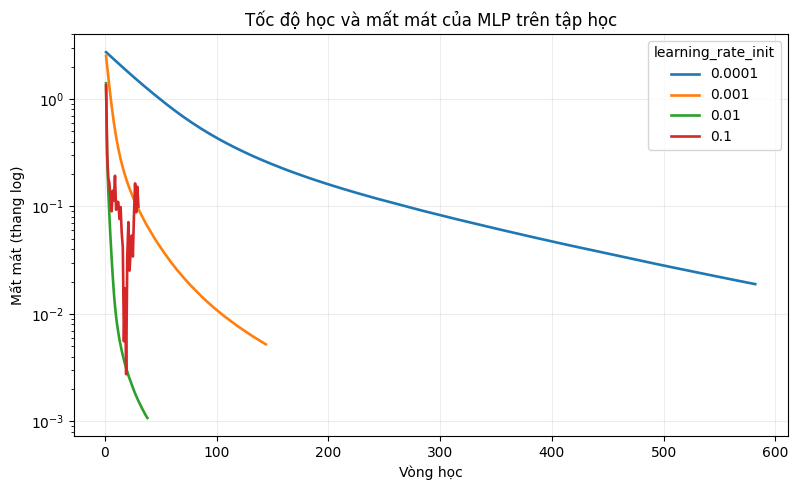

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

anh, chu_so = load_digits(return_X_y=True)
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    anh, chu_so, test_size=0.25, random_state=17, stratify=chu_so
)

ket_qua = []
fig, ax = plt.subplots(figsize=(8.1, 5.0))
for toc_do in (0.0001, 0.001, 0.01, 0.1):
    mo_hinh = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(100,), solver="adam", learning_rate_init=toc_do,
            max_iter=1000, random_state=0,
        ),
    ).fit(X_hoc, y_hoc)
    mlp = mo_hinh[-1]
    mat_mat = mlp.loss_curve_
    ket_qua.append({
        "learning_rate_init": toc_do,
        "Số vòng": mlp.n_iter_,
        "Mất mát cuối": mat_mat[-1],
        "Accuracy kiểm tra": mo_hinh.score(X_kiem_tra, y_kiem_tra),
    })
    ax.plot(range(1, len(mat_mat) + 1), mat_mat, linewidth=1.9, label=f"{toc_do:g}")

bang = pd.DataFrame(ket_qua)
print(bang.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
ax.set(title="Tốc độ học và mất mát của MLP trên tập học",
       xlabel="Vòng học", ylabel="Mất mát (thang log)", yscale="log")
ax.grid(alpha=0.22)
ax.legend(title="learning_rate_init")
fig.tight_layout()
tep_hinh = Path("figures/toc_do_hoc.png")
tep_hinh.parent.mkdir(exist_ok=True)
fig.savefig(tep_hinh, dpi=160)
print(f"Đã lưu {tep_hinh.as_posix()}")
plt.show()

**Giải thích và nhận xét**

Tốc độ `0.0001` giảm mất mát chậm và cần **582 vòng**, nhưng cho accuracy kiểm tra cao nhất trong bốn giá trị đã thử (`0.9889`). `0.001` cần 144 vòng và đạt `0.9844`. Với `0.01`, mất mát cuối thấp nhất (`0.0011`) sau 38 vòng, còn accuracy kiểm tra là `0.9778`. Mất mát ghi trong biểu đồ thuộc tập học.

Bước quá nhỏ cần nhiều lần cập nhật. Bước quá lớn có thể vượt qua vùng mất mát thấp và dao động. Đường `0.1` dao động rõ, dừng sau 30 vòng với mất mát `0.0996` và accuracy kiểm tra thấp nhất (`0.9489`).

## Bài 5. Dò lưới cho mạng nơ-ron

**Đề bài**

Dùng `GridSearchCV` với pipeline chuẩn hoá và MLP. Thử bốn kiến trúc `(10,)`, `(50,)`, `(100,)`, `(50, 50)` và ba giá trị `alpha` là `0.0001`, `0.01`, `1`. Đánh giá cấu hình được chọn trên tập kiểm tra và so với SVM.

In [5]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

anh, chu_so = load_digits(return_X_y=True)
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    anh, chu_so, test_size=0.25, random_state=17, stratify=chu_so
)

mo_hinh = make_pipeline(
    StandardScaler(),
    MLPClassifier(solver="adam", max_iter=1000, random_state=0),
)
luoi = {
    "mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
    "mlpclassifier__alpha": [0.0001, 0.01, 1],
}
tim = GridSearchCV(mo_hinh, luoi, cv=5, scoring="accuracy")
tim.fit(X_hoc, y_hoc)

bang = pd.DataFrame(tim.cv_results_)[[
    "param_mlpclassifier__hidden_layer_sizes", "param_mlpclassifier__alpha",
    "mean_test_score", "std_test_score", "rank_test_score",
]].rename(columns={
    "param_mlpclassifier__hidden_layer_sizes": "Lớp ẩn",
    "param_mlpclassifier__alpha": "Alpha",
    "mean_test_score": "Accuracy CV",
    "std_test_score": "Độ lệch chuẩn CV",
    "rank_test_score": "Hạng",
})
print(bang.sort_values("Hạng", kind="stable").to_string(
    index=False, float_format=lambda x: f"{x:.4f}",
))

# GridSearchCV đã fit lại cặp tốt nhất trên toàn bộ tập học.
acc_mlp = tim.score(X_kiem_tra, y_kiem_tra)
acc_svm = SVC().fit(X_hoc, y_hoc).score(X_kiem_tra, y_kiem_tra)
print(f"\nCấu hình tốt nhất: {tim.best_params_}")
print(f"Accuracy CV tốt nhất: {tim.best_score_:.4f}")
print(f"Accuracy kiểm tra MLP: {acc_mlp:.4f} ({round(acc_mlp * len(y_kiem_tra))}/{len(y_kiem_tra)})")
print(f"Accuracy kiểm tra SVM RBF: {acc_svm:.4f} ({round(acc_svm * len(y_kiem_tra))}/{len(y_kiem_tra)})")
print(f"Chênh lệch MLP - SVM: {(acc_mlp - acc_svm) * 100:+.2f} điểm phần trăm")

  Lớp ẩn  Alpha  Accuracy CV  Độ lệch chuẩn CV  Hạng
   (50,) 1.0000       0.9785            0.0055     1
(50, 50) 1.0000       0.9777            0.0041     2
  (100,) 1.0000       0.9777            0.0053     3
  (100,) 0.0001       0.9755            0.0080     4
   (50,) 0.0100       0.9755            0.0038     4
  (100,) 0.0100       0.9755            0.0080     4
   (50,) 0.0001       0.9740            0.0047     7
(50, 50) 0.0001       0.9681            0.0107     8
(50, 50) 0.0100       0.9681            0.0107     8
   (10,) 1.0000       0.9651            0.0086    10
   (10,) 0.0100       0.9488            0.0159    11
   (10,) 0.0001       0.9480            0.0161    12

Cấu hình tốt nhất: {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)}
Accuracy CV tốt nhất: 0.9785
Accuracy kiểm tra MLP: 0.9822 (442/450)
Accuracy kiểm tra SVM RBF: 0.9911 (446/450)
Chênh lệch MLP - SVM: -0.89 điểm phần trăm


**Giải thích và nhận xét**

Dò 12 cặp tham số bằng kiểm định chéo 5 phần trên 1.347 ảnh tập học. Mỗi fold fit lại cả bộ chuẩn hoá và MLP, nên ảnh kiểm định của fold không tham gia ước lượng các tham số chuẩn hoá. Cấu hình được chọn là (50,), alpha 1, accuracy CV 0.9785. Sau khi chọn, GridSearchCV fit lại cấu hình này trên toàn bộ tập học.

Trên 450 ảnh kiểm tra, MLP đạt 0.9822 (442/450 đúng) và SVM RBF đạt 0.9911 (446/450 đúng). MLP thấp hơn SVM 0,89 điểm phần trăm. SVM dùng đúng cấu hình SVC() của Bước 5 và cùng phép chia dữ liệu.

## Bài 6. Mạng nơ-ron cho hồi quy

**Đề bài**

Dùng `MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)` có chuẩn hoá trên bộ giá nhà Lab 1. So MAE kiểm tra với hồi quy tuyến tính, dự đoán giá căn 250 m² và giải thích giới hạn của việc ngoại suy.

In [6]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

du_lieu = pd.read_csv("data/gia_nha.csv")
# Dùng biến diện tích và cách chia của bước đánh giá mô hình ở Lab 1.
dien_tich = du_lieu[["dien_tich"]]
gia_nha = du_lieu["gia"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    dien_tich, gia_nha, test_size=0.2, random_state=42
)

tuyen_tinh = LinearRegression().fit(X_hoc, y_hoc)
mang = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0),
).fit(X_hoc, y_hoc)

can_250 = pd.DataFrame({"dien_tich": [250.0]})
ket_qua = []
for ten, mo_hinh in [("Hồi quy tuyến tính", tuyen_tinh), ("MLPRegressor", mang)]:
    ket_qua.append({
        "Mô hình": ten,
        "MAE kiểm tra (tỷ đồng)": mean_absolute_error(y_kiem_tra, mo_hinh.predict(X_kiem_tra)),
        "Dự đoán 250 m² (tỷ đồng)": mo_hinh.predict(can_250)[0],
    })

print(f"Tập học: {len(X_hoc)} căn, tập kiểm tra: {len(X_kiem_tra)} căn")
print(f"Diện tích tập học: {X_hoc['dien_tich'].min():.1f}–{X_hoc['dien_tich'].max():.1f} m²")
print(f"Diện tích toàn bộ CSV: {dien_tich['dien_tich'].min():.1f}–{dien_tich['dien_tich'].max():.1f} m²")
print(pd.DataFrame(ket_qua).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

dien_tich_lon = pd.DataFrame({"dien_tich": [200.0, 225.0, 250.0]})
print("\nĐối chiếu xu hướng ngoài phạm vi tập học (tỷ đồng)")
print(dien_tich_lon.assign(
    tuyen_tinh=tuyen_tinh.predict(dien_tich_lon), MLP=mang.predict(dien_tich_lon),
).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Tập học: 48 căn, tập kiểm tra: 12 căn
Diện tích tập học: 37.6–117.5 m²
Diện tích toàn bộ CSV: 35.5–117.5 m²
           Mô hình  MAE kiểm tra (tỷ đồng)  Dự đoán 250 m² (tỷ đồng)
Hồi quy tuyến tính                  0.2578                   19.9139
      MLPRegressor                  0.5008                   28.1758

Đối chiếu xu hướng ngoài phạm vi tập học (tỷ đồng)
 dien_tich  tuyen_tinh     MLP
  200.0000     16.0221 21.3555
  225.0000     17.9680 24.7216
  250.0000     19.9139 28.1758


**Giải thích và nhận xét**

Hai mô hình dùng cùng một biến diện tích và cùng cách chia 48 căn học, 12 căn kiểm tra. MLP chuẩn hoá diện tích bằng giá trị trung bình và độ lệch chuẩn của tập học. MAE của hồi quy tuyến tính là **0,2578 tỷ**, thấp hơn **0,5008 tỷ** của MLP.

Tại **250 m²**, hồi quy tuyến tính dự đoán **19,9139 tỷ** còn MLP dự đoán **28,1758 tỷ**. Diện tích lớn nhất trong tập học và toàn bộ CSV đều chỉ **117,5 m²**. Bảng các mốc 200, 225 và 250 m² cho thấy dự đoán MLP tăng nhanh hơn. Hồi quy tuyến tính giữ nguyên hệ số góc. Các nơ-ron ReLU khiến đầu ra MLP là hàm tuyến tính từng đoạn của diện tích đã chuẩn hoá, nên độ dốc ngoài vùng đã học có thể khác. Trên tập kiểm tra hiện có, tuyến tính có MAE thấp hơn. Độ chính xác ở 250 m² cần giá thật của các căn có diện tích tương đương để đánh giá.